# 英国道路伤人事故数据清洗与探索分析

2024—2025 年。目标 `is_severe`：原事故严重程度 1（致死）或 2（重伤）记为 1，3（轻伤）记为 0。

本研究描述已记录伤人事故的严重程度，原始数据没有未发生事故的对照道路时段。主训练样本要求六项天气都有观测来源，并且原值质控或实测推导输入质控能够核对。全部事故和排除原因另存，原始三份 CSV 不改写。

使用 Python 3.12；依赖见 `requirements-data.txt`。从上到下运行即可；第一格用 Python 调用 DVC，原始数据和代码未变化时会直接复用已生成的结果。

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "schema.json").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
subprocess.run([sys.executable, "-m", "src.manage_data", "build"], cwd=ROOT, check=True)
DATA = ROOT / "data"
quality = json.loads((DATA / "quality_report.json").read_text(encoding="utf-8"))
split_report = json.loads((DATA / "split_report.json").read_text(encoding="utf-8"))
preprocessing = json.loads((DATA / "preprocessing_report.json").read_text(encoding="utf-8"))
insights = json.loads((DATA / "eda_figures/insights.json").read_text(encoding="utf-8"))
contract = json.loads((ROOT / "schema.json").read_text(encoding="utf-8"))

## 1 读取原始数据与清洗结果

原始事故 CSV 按文本读取，保护事故编号和分类编码。清洗管道把未知码转为缺失，按各来源的标记排除不合格天气值；不使用预报或网格估计补天气。站点气压不混作海平面气压，COSMOS 的小时雨量只累计同一雨量计相邻两段合格的半小时观测。详细 Python 实现见 `src/data_pipeline.py`。

事故时间按 `Europe/London` 转为 UTC，无法唯一判断的夏令时重复小时保留原因，不猜测。

In [2]:
raw_preview = pd.read_csv(DATA / "raw/dft-road-casualty-statistics-collision-2024.csv", dtype="string", nrows=5)
display(raw_preview[["collision_index", "date", "time", "collision_severity", "weather_conditions", "light_conditions"]])
display(pd.DataFrame({"指标": ["事故原始记录", "天气原始记录", "能取得观测天气的事故", "六项观测天气齐全", "六项质控可核对"],
    "数量": [quality["collisions"]["raw_rows"], quality["weather"]["input_rows"],
            quality["matching"]["any_observed_weather"], quality["matching"]["observed_core6_complete"],
            quality["matching"]["core6_all_qc_checkable"]]}))
display(pd.DataFrame(list(quality["matching"]["exclusion_reasons"].items()), columns=["未进入主模型的原因（空白为可用）", "数量"]))

,collision_index,date,time,collision_severity,weather_conditions,light_conditions
0,202417H100324,12/01/2024,19:30,2,1,4
1,202417M110024,01/07/2024,22:15,3,1,4
2,2024480537342,18/09/2024,17:00,3,1,1
3,202417M105824,04/05/2024,16:10,3,1,1
4,202417M114324,30/08/2024,20:16,3,1,4


,指标,数量
0,事故原始记录,202452
1,天气原始记录,369383
2,能取得观测天气的事故,202032
3,六项观测天气齐全,180518
4,六项质控可核对,164860


,未进入主模型的原因（空白为可用）,数量
0,,164860
1,core_weather_incomplete,21914
2,weather_qc_not_exposed,15658
3,unresolved_local_time,18
4,invalid_coordinates,2


## 2 观测范围与天文时间

天气匹配沿用 40 公里、事故前后各 60 分钟的要求。选取顺序为观测字段数、质控可核对字段数、推导字段数、WGS84 距离和时间差。允许事故之后的观测，因此本版用于回顾性严重程度研究，不能直接声称满足实时预测的信息可得性。

日出、日落与民用、航海、天文曙暮光由 Astral 3.2 在每次事故的坐标和日期计算，原件中的天气值与这些天文计算值分开处理。未纳入地形遮挡，观测高度按 0 米；高纬夏季不存在的天文曙暮光事件保持为空，不作为需要补齐的坏数据。

In [3]:
astronomy_columns = ["collision_index", "collision_datetime_utc", "latitude", "longitude", "sunrise_utc", "sunset_utc", "civil_dawn_utc", "civil_dusk_utc", "astronomical_dawn_utc", "astronomical_dusk_utc"]
display(pd.read_csv(DATA / "processed/collisions_clean.csv", dtype={"collision_index": str}, usecols=astronomy_columns, nrows=5))

,collision_index,collision_datetime_utc,longitude,latitude,sunrise_utc,sunset_utc,civil_dawn_utc,civil_dusk_utc,astronomical_dawn_utc,astronomical_dusk_utc
0,202417H100324,2024-01-12 19:30:00+00:00,-1.22869,54.65155,2024-01-12 08:22:29.114521+00:00,2024-01-12 16:03:58.164334+00:00,2024-01-12 07:38:35.819104+00:00,2024-01-12 16:47:52.299502+00:00,2024-01-12 06:09:44.444530+00:00,2024-01-12 18:16:46.472920+00:00
1,202417M110024,2024-07-01 21:15:00+00:00,-1.22715,54.56618,2024-07-01 03:34:13.777134+00:00,2024-07-01 20:43:07.808729+00:00,2024-07-01 02:37:35.935036+00:00,2024-07-01 21:39:32.457189+00:00,NaN,NaN
2,2024480537342,2024-09-18 16:00:00+00:00,-0.10449,51.50852,2024-09-18 05:41:02.038432+00:00,2024-09-18 18:06:45.769971+00:00,2024-09-18 05:06:52.657648+00:00,2024-09-18 18:40:48.055683+00:00,2024-09-18 03:45:18.059113+00:00,2024-09-18 20:01:55.683553+00:00
3,202417M105824,2024-05-04 15:10:00+00:00,-1.22319,54.56529,2024-05-04 04:19:42.192653+00:00,2024-05-04 19:44:49.307003+00:00,2024-05-04 03:35:41.174785+00:00,2024-05-04 20:29:10.530220+00:00,2024-05-04 01:06:53.251680+00:00,2024-05-04 23:02:57.742182+00:00
4,202417M114324,2024-08-30 19:16:00+00:00,-1.21662,54.57314,2024-08-30 05:09:24.004860+00:00,2024-08-30 19:00:04.701913+00:00,2024-08-30 04:30:31.434159+00:00,2024-08-30 19:38:44.086699+00:00,2024-08-30 02:47:58.279919+00:00,2024-08-30 21:20:09.285314+00:00


## 3 固定 train val test 划分

按完整 UTC 日期排序，目标比例为 70% / 15% / 15%。两条分界线各向前后留 60 分钟空档，防止同一条天气观测同时进入不同集合。实际数量受整日边界和空档影响。任何填补中位数、标准化参数、类别集合都只从训练集学习。

In [4]:
display(pd.DataFrame(split_report["splits"]).T[["rows", "positive_rows", "positive_rate", "start_utc", "end_utc"]])
print("UTC 分界：", split_report["boundaries_utc"])
print("边界空档暂不使用的记录：", split_report["boundary_gap_rows"])
assert split_report["accident_ids_disjoint"] and split_report["weather_ids_disjoint"]

,rows,positive_rows,positive_rate,start_utc,end_utc
train,115535,28862,0.249812,2024-01-01T00:02:00+00:00,2025-06-14T22:52:00+00:00
val,24636,6599,0.26786,2025-06-15T01:06:00+00:00,2025-09-24T22:59:00+00:00
test,24679,6287,0.254751,2025-09-25T02:00:00+00:00,2025-12-31T23:59:00+00:00


UTC 分界： ['2025-06-15T00:00:00+00:00', '2025-09-25T00:00:00+00:00']
边界空档暂不使用的记录： 10


## 4 简单 EDA

下面 7 张图的严重程度分析均只使用训练集。区间为二项比例的 95% Wilson 区间。图中比例反映已记录伤人事故内的严重程度构成，没有道路暴露量分母，不能解释为事故发生风险或因果效应。

### 图 1 严重程度分布

轻伤与致死或重伤的样本比例，供后续建模确定类别不平衡处理。

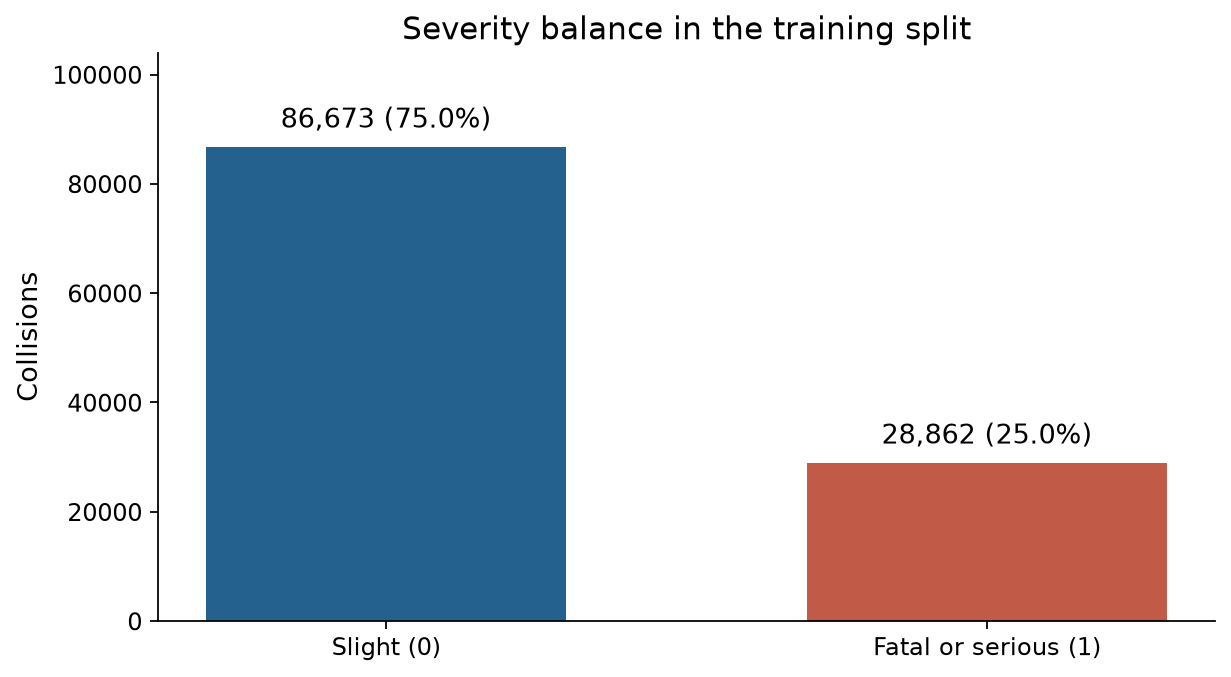

In [5]:
display(Image(filename=str(DATA / "eda_figures" / insights["figures"][0]["file"]), width=820))

### 图 2 月份分布

分别显示事故数量和严重事故比例，避免把高数量月份直接当作严重程度更高。

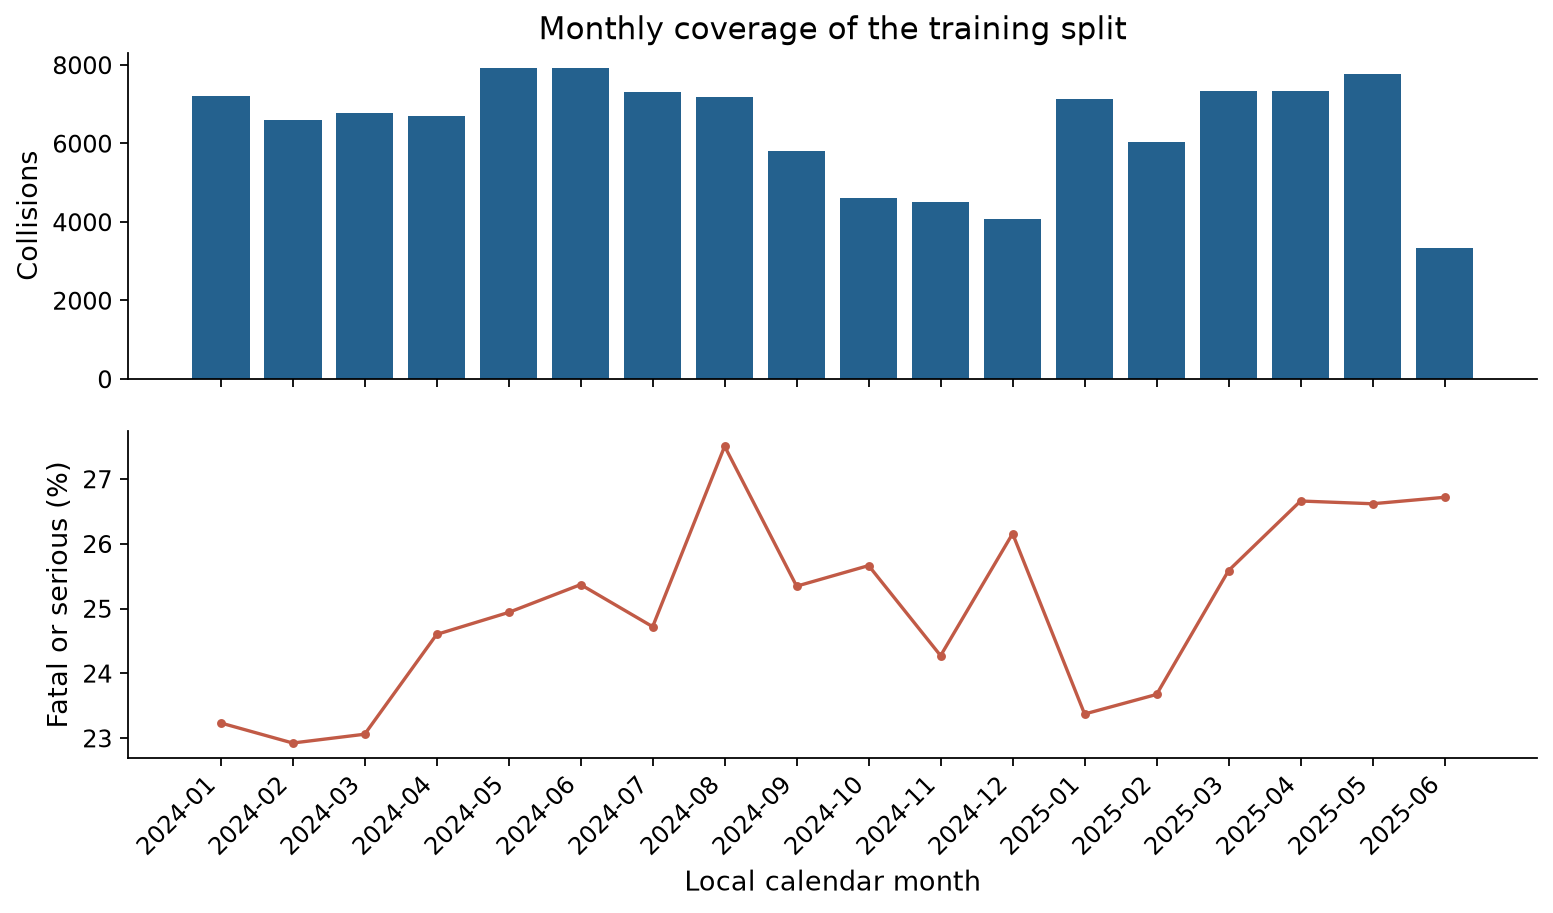

In [6]:
display(Image(filename=str(DATA / "eda_figures" / insights["figures"][1]["file"]), width=820))

### 图 3 小时分布

小时按英国当地时间表示，置信区间帮助辨认夜间小样本波动。

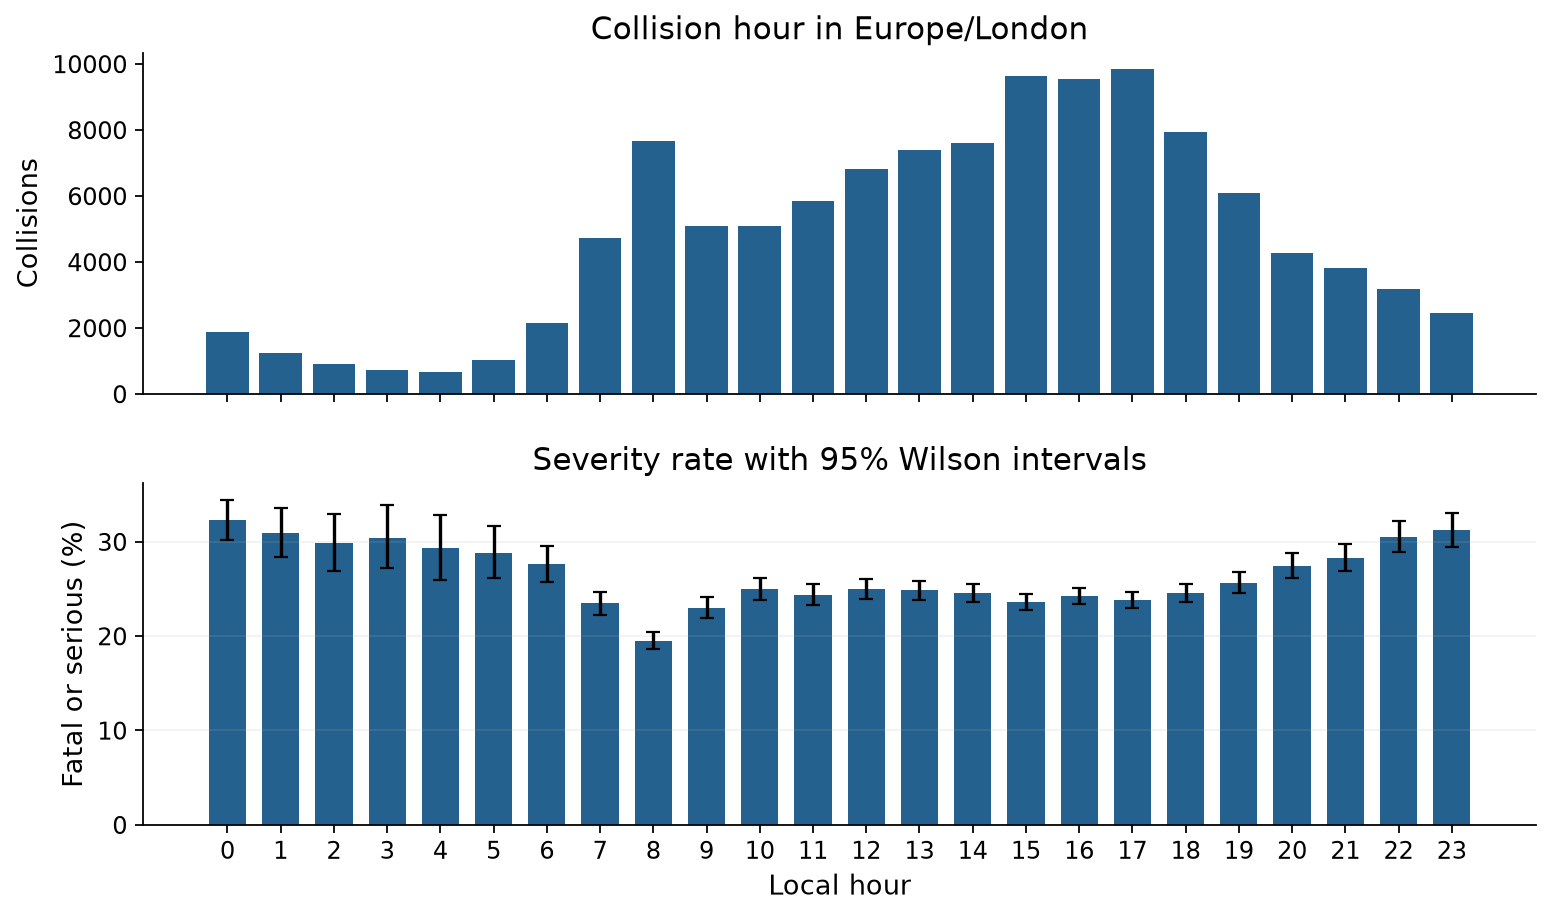

In [7]:
display(Image(filename=str(DATA / "eda_figures" / insights["figures"][2]["file"]), width=820))

### 图 4 限速与严重程度

限速单位仍为 mph。图中关系可能同时受道路类型、交通参与者和地理覆盖影响。

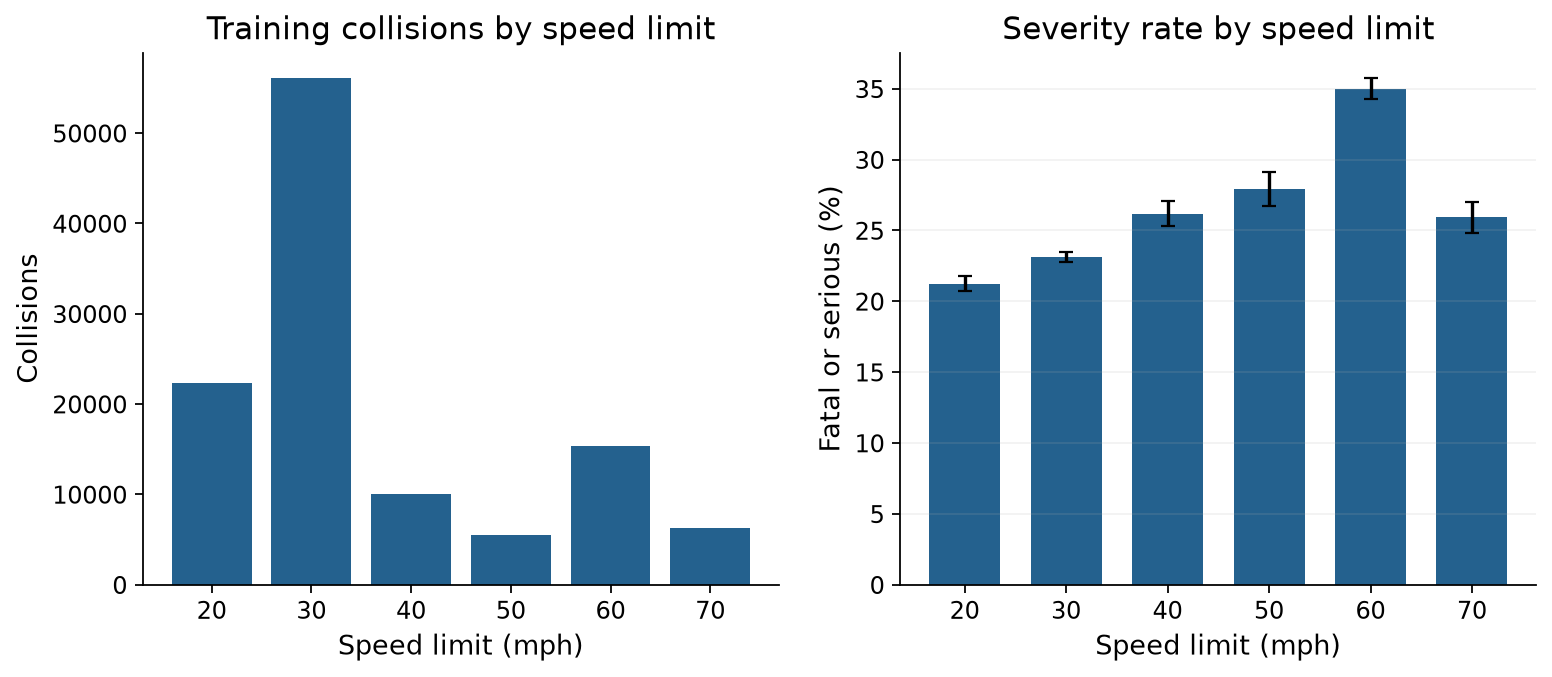

In [8]:
display(Image(filename=str(DATA / "eda_figures" / insights["figures"][3]["file"]), width=820))

### 图 5 缺失情况

显示填补前的模型输入缺失。主模型六项天气完整，道路信息仍可缺失；填补参数只拟合训练集。

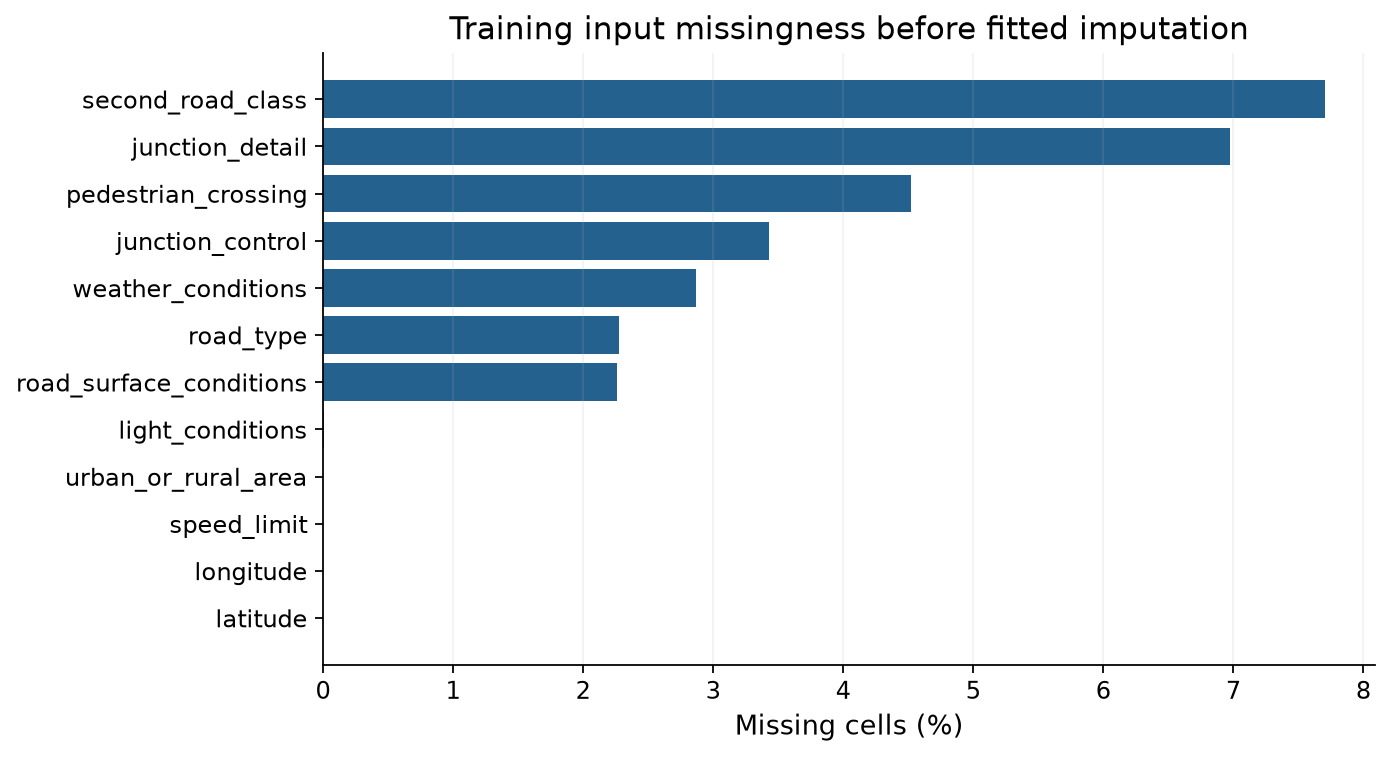

In [9]:
display(Image(filename=str(DATA / "eda_figures" / insights["figures"][4]["file"]), width=820))

### 图 6 气温与降水

保留测站观测的单位与累计时段。箱线图为便于阅读不绘制离群点，但没有据此删掉数据。

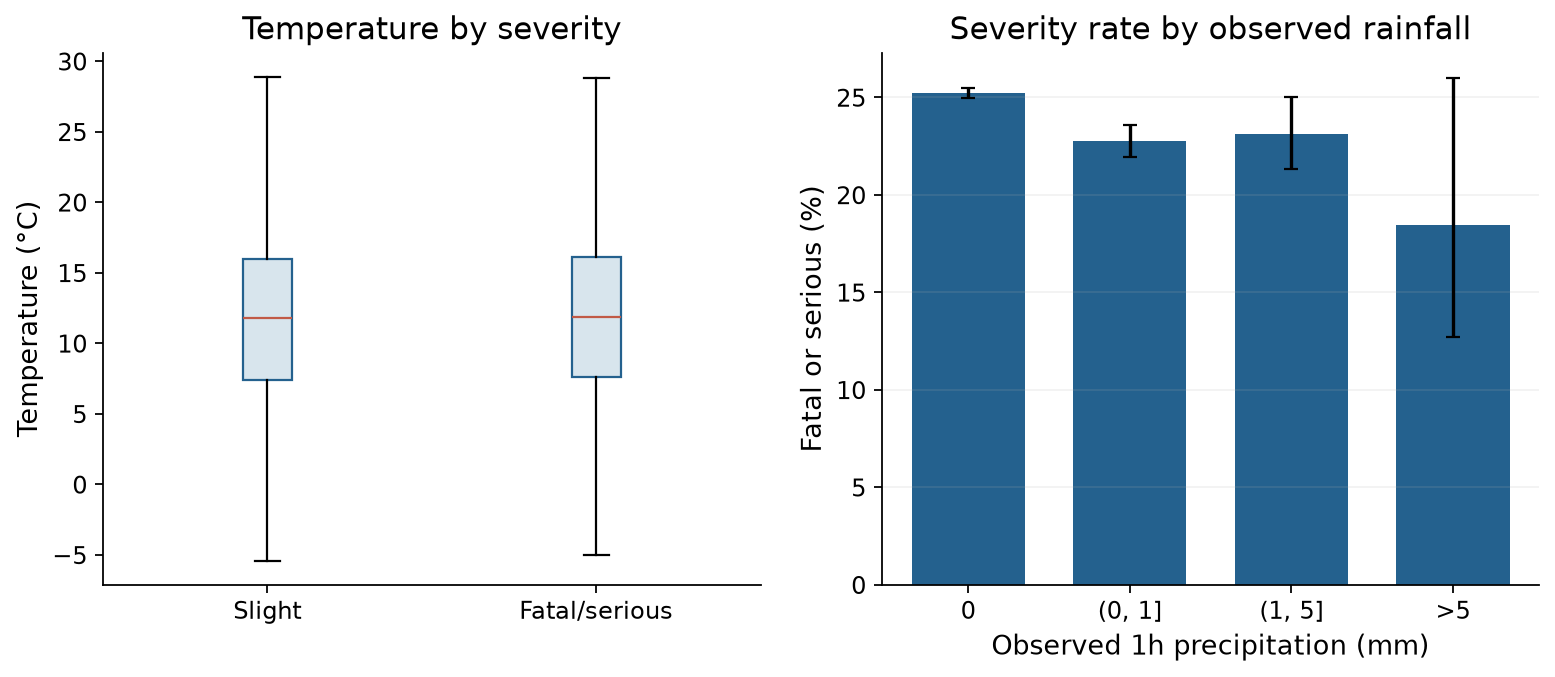

In [10]:
display(Image(filename=str(DATA / "eda_figures" / insights["figures"][5]["file"]), width=820))

### 图 7 昼夜与曙暮光

采用每次事故坐标的太阳高度，而不是用全国统一的固定小时划分白天黑夜。

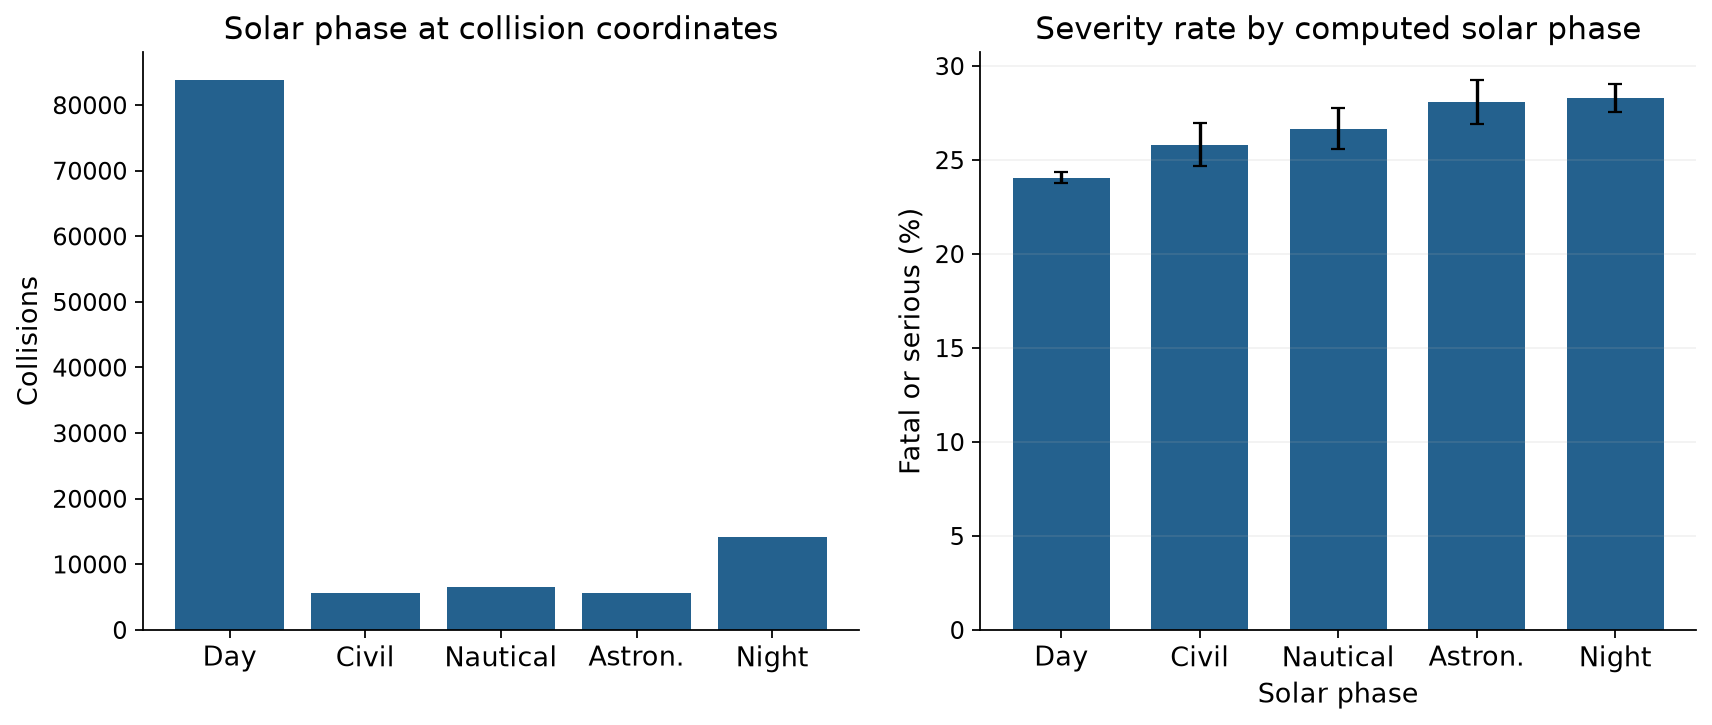

In [11]:
display(Image(filename=str(DATA / "eda_figures" / insights["figures"][6]["file"]), width=820))

## 5 给 B C D 同学的统一 Python 接口

`load_splits()` 返回三个固定集合，各自为 `(X, y)`。`build_pipeline(estimator)` 把日历周期、太阳高度、风向分量、缺失处理、标准化和 OneHotEncoder 放入同一个 sklearn Pipeline。B 传入自己的分类器再 `fit(X_train, y_train)`；C 和 D 复用已保存的完整模型，不能在验证集、测试集或线上重新拟合预处理。

特征使用允许名单。严重程度及其调整字段、伤亡人数、事故编号、警察到场情况和匹配质量字段不会进入模型。未知类别可以编码，数值缺失只在模型处理阶段使用训练集中位数，原始实测天气不因此被改写。

In [12]:
from src.features import build_pipeline, load_splits

splits = load_splits()
X_train, y_train = splits["train"]
X_val, y_val = splits["val"]
X_test, y_test = splits["test"]
display(pd.DataFrame(preprocessing["shapes"], index=["rows", "encoded_features"]).T)
print("编码后特征数：", preprocessing["encoded_feature_count"])
print("只在训练集拟合：", preprocessing["fit_population"])
print("统一预处理步骤：", [name for name, step in build_pipeline().steps])
assert preprocessing["validation_test_statistics_unchanged"]
assert preprocessing["target_and_outcome_fields_excluded"]

# B 的用法示例（训练模型属于 B 的任务，这里不自动训练分类器）：
# from sklearn.linear_model import LogisticRegression
# model = build_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced"))
# model.fit(X_train, y_train)
# probabilities = model.predict_proba(X_val)[:, 1]

,rows,encoded_features
train,115535,93
val,24636,93
test,24679,93


编码后特征数： 93
只在训练集拟合： train_only
统一预处理步骤： ['features', 'preprocess']


## 6 校验与数据版本

`schema.json` 是统一字段约定，`src/validation.py` 使用 pandera 检查编码、数值范围、编号唯一性、UTC 和主模型天气完整性。`dvc.yaml` 与 `dvc.lock` 记录原始 CSV、代码依赖和派生数据哈希。原始 CSV 已在 Git 中，派生大文件使用 DVC 缓存。

本机有本地 DVC 备份，未把它冒充团队共享云存储。其他同学没有这台电脑的缓存时，直接运行 `python -m src.manage_data build` 从仓库的原始 CSV 重建即可。

参考：[scikit-learn 防泄漏与 Pipeline](https://scikit-learn.org/stable/common_pitfalls.html)、[pandera DataFrameSchema](https://pandera.readthedocs.io/en/stable/dataframe_schemas.html)、[DVC](https://doc.dvc.org/user-guide)、[Astral 3.2](https://sffjunkie.github.io/astral/package.html)。